RAILPULSE AI — PCA AND K-MEANS CLUSTERING
Internal training trains: 2012
Reserved final-test trains: 630

Sampling internal training observations...
Processed 300,000 source rows
Processed 600,000 source rows
Processed 900,000 source rows
Processed 1,200,000 source rows

SAMPLING COMPLETED
Internal training rows scanned: 699,293
Clustering sample size: 30,000

Transformed feature summary:
       log_current_arr_delay  log_distance_to_next  log_current_distance  \
count              30000.000             30000.000             30000.000   
mean                   2.020                 3.319                 5.532   
std                    1.740                 0.881                 1.646   
min                    0.000                 0.000                 0.000   
25%                    0.000                 2.708                 4.970   
50%                    2.197                 3.332                 5.838   
75%                    3.332                 3.932                 6.605   


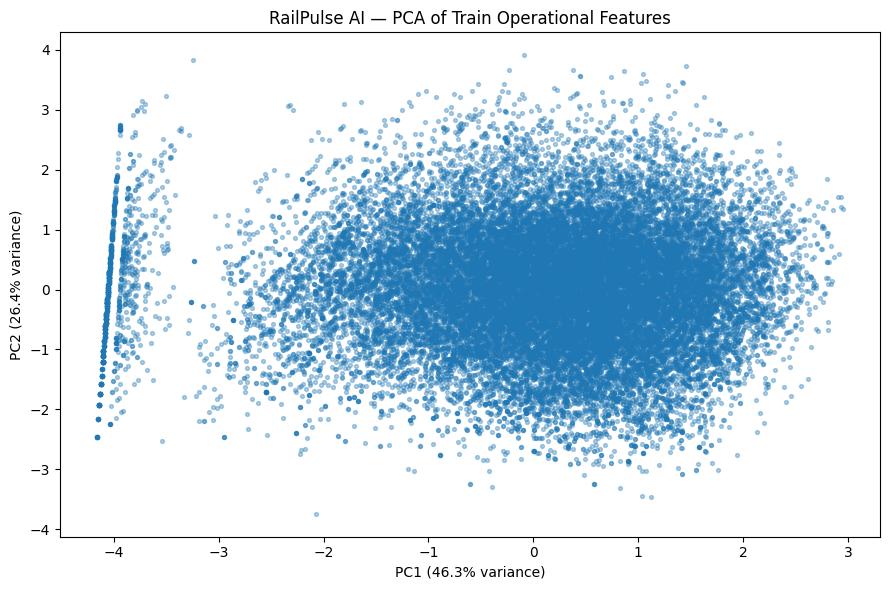


PCA figure saved: ../outputs/figures\06_pca_projection.png

Evaluating K-Means cluster counts...

Testing k = 2
Inertia: 85943.3
Silhouette: 0.2869
Davies-Bouldin: 1.346

Testing k = 3
Inertia: 66128.33
Silhouette: 0.2802
Davies-Bouldin: 1.2725

Testing k = 4
Inertia: 55546.13
Silhouette: 0.2701
Davies-Bouldin: 1.189

Testing k = 5
Inertia: 46670.03
Silhouette: 0.2715
Davies-Bouldin: 1.0909

Testing k = 6
Inertia: 40744.2
Silhouette: 0.2635
Davies-Bouldin: 1.0889

K-MEANS CLUSTER SELECTION METRICS
 K    Inertia  Silhouette_Score  Davies_Bouldin_Score
 2 85943.3047            0.2869                1.3460
 3 66128.3281            0.2802                1.2725
 4 55546.1328            0.2701                1.1890
 5 46670.0312            0.2715                1.0909
 6 40744.1953            0.2635                1.0889


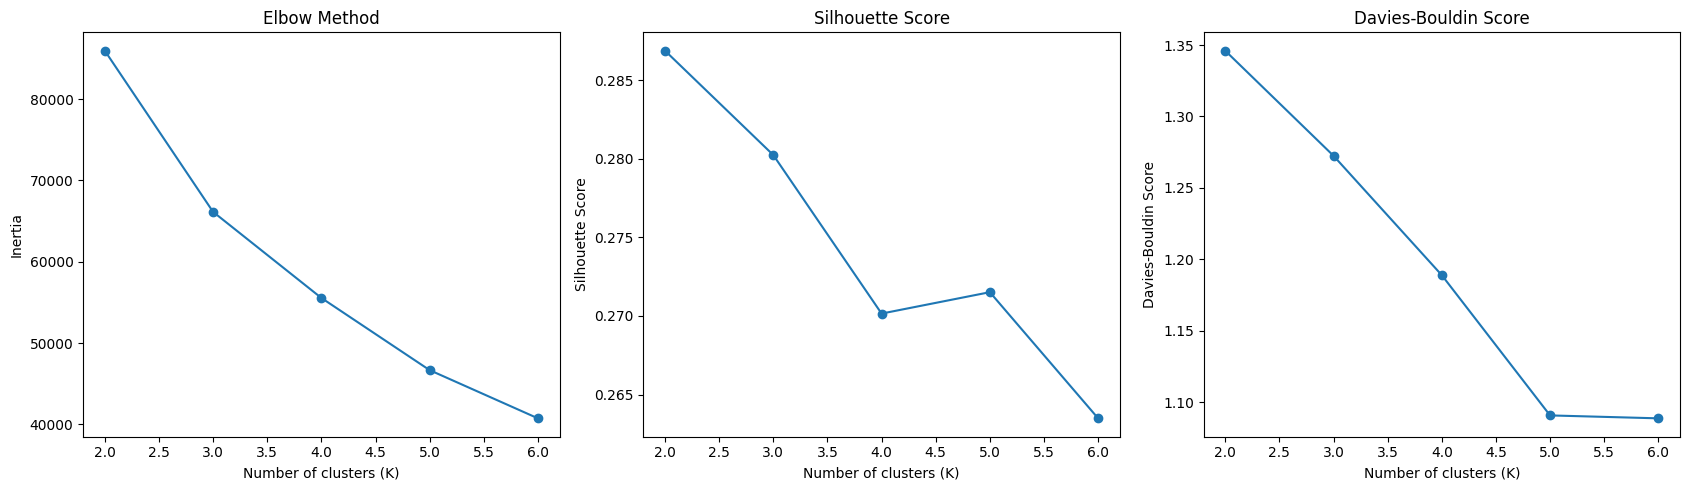


Cluster selection figure saved: ../outputs/figures\07_cluster_selection_metrics.png

Best silhouette-based K: 2

Final cluster sizes:
cluster
0     8449
1    21551
Name: count, dtype: int64

CLUSTER PROFILES — ORIGINAL DATA UNITS
 cluster  observations  mean_current_delay  median_current_delay  mean_next_delay  median_next_delay  mean_distance_to_next  median_distance_to_next  mean_current_distance  mean_current_sequence  percentage
       0          8449               14.72                  6.00            17.63               8.00                  39.31                    25.00                  83.96                   3.91       28.16
       1         21551               36.83                 10.00            36.20               9.00                  40.39                    28.00                 702.04                  21.24       71.84


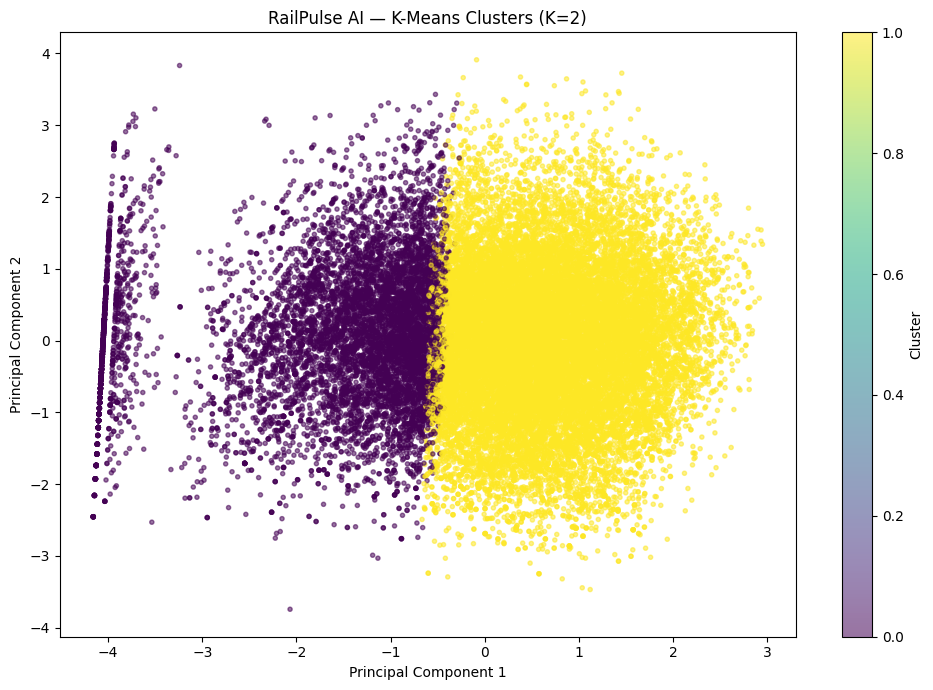


Cluster figure saved: ../outputs/figures\08_kmeans_pca_clusters.png

Clustered sample saved: ../outputs/tables\clustered_training_sample.csv

PCA AND CLUSTERING COMPLETED
Sample observations: 30000
Features used for clustering: 4
Selected cluster count: 2
PCA variance explained: 72.67 %

Important:
Clustering used predictors only.
The next-station delay was used only for cluster profiling.
Clusters are exploratory patterns, not official railway categories.

All PCA and clustering outputs saved.


In [1]:

# ============================================================
# RAILPULSE AI — PCA AND K-MEANS CLUSTERING
# Unsupervised Operational Pattern Discovery
# ============================================================

import os
import gc
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score
)

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

DATA_PATH = "../data/processed/railpulse_model_features.csv"

MANIFEST_PATH = (
    "../outputs/tables/three_way_train_split_manifest.csv"
)

OUTPUT_DIR = "../outputs/tables"
FIGURE_DIR = "../outputs/figures"

os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(FIGURE_DIR, exist_ok=True)

CHUNK_SIZE = 100_000
RANDOM_STATE = 42

SAMPLE_PER_CHUNK = 5_000
FINAL_SAMPLE_SIZE = 30_000

FEATURES = [
    "current_arr_delay",
    "distance_to_next",
    "current_distance",
    "current_sequence"
]

TARGET_COL = "next_arr_delay"

USE_COLS = (
    ["train"] + FEATURES + [TARGET_COL]
)

# ------------------------------------------------------------
# 2. LOAD INTERNAL TRAINING IDS
# ------------------------------------------------------------

print("=" * 75)
print("RAILPULSE AI — PCA AND K-MEANS CLUSTERING")
print("=" * 75)

manifest = pd.read_csv(
    MANIFEST_PATH,
    dtype={"train": str}
)

internal_train_ids = set(
    manifest.loc[
        manifest["split"] == "internal_train",
        "train"
    ]
)

reserved_ids = set(
    manifest.loc[
        manifest["split"] == "reserved_final_test",
        "train"
    ]
)

assert internal_train_ids.isdisjoint(reserved_ids)

print("Internal training trains:", len(internal_train_ids))
print("Reserved final-test trains:", len(reserved_ids))

# ------------------------------------------------------------
# 3. LOAD A REPRESENTATIVE SAMPLE IN CHUNKS
# ------------------------------------------------------------

print("\nSampling internal training observations...")

sample_parts = []
total_training_rows = 0

rng = np.random.default_rng(RANDOM_STATE)

for chunk_no, chunk in enumerate(
    pd.read_csv(
        DATA_PATH,
        usecols=USE_COLS,
        dtype={"train": str},
        chunksize=CHUNK_SIZE
    ),
    start=1
):

    mask = chunk["train"].isin(
        internal_train_ids
    )

    train_chunk = chunk.loc[mask]

    total_training_rows += len(train_chunk)

    if len(train_chunk) > SAMPLE_PER_CHUNK:

        selected = train_chunk.sample(
            n=SAMPLE_PER_CHUNK,
            random_state=RANDOM_STATE + chunk_no
        )

    else:
        selected = train_chunk

    sample_parts.append(
        selected.drop(columns=["train"])
    )

    if chunk_no % 3 == 0:
        print(
            f"Processed {chunk_no * CHUNK_SIZE:,} source rows"
        )

sample_df = pd.concat(
    sample_parts,
    ignore_index=True
)

del sample_parts
gc.collect()

# Limit final sample if necessary
if len(sample_df) > FINAL_SAMPLE_SIZE:

    sample_df = sample_df.sample(
        n=FINAL_SAMPLE_SIZE,
        random_state=RANDOM_STATE
    ).reset_index(drop=True)

print("\nSAMPLING COMPLETED")
print("Internal training rows scanned:", f"{total_training_rows:,}")
print("Clustering sample size:", f"{len(sample_df):,}")

# ------------------------------------------------------------
# 4. PREPARE FEATURES
# ------------------------------------------------------------

X_original = sample_df[FEATURES].copy()

# Log transformation reduces skewness and extreme-value influence
X_transformed = pd.DataFrame({
    "log_current_arr_delay": np.log1p(
        X_original["current_arr_delay"]
    ),
    "log_distance_to_next": np.log1p(
        X_original["distance_to_next"]
    ),
    "log_current_distance": np.log1p(
        X_original["current_distance"]
    ),
    "log_current_sequence": np.log1p(
        X_original["current_sequence"]
    )
})

print("\nTransformed feature summary:")
print(
    X_transformed.describe().round(3)
)

# ------------------------------------------------------------
# 5. STANDARDIZE FEATURES
# ------------------------------------------------------------

scaler = StandardScaler()

X_scaled = scaler.fit_transform(
    X_transformed
).astype(np.float32)

print("\nScaled feature shape:", X_scaled.shape)

# ------------------------------------------------------------
# 6. PCA — TWO-DIMENSIONAL REDUCTION
# ------------------------------------------------------------

print("\nRunning PCA...")

pca = PCA(
    n_components=2,
    random_state=RANDOM_STATE
)

X_pca = pca.fit_transform(
    X_scaled
)

explained_variance = (
    pca.explained_variance_ratio_
)

total_explained = explained_variance.sum()

print("\nPCA RESULTS")
print("PC1 explained variance:", round(
    explained_variance[0] * 100, 3
), "%")

print("PC2 explained variance:", round(
    explained_variance[1] * 100, 3
), "%")

print("Total explained variance:", round(
    total_explained * 100, 3
), "%")

# Save explained variance
pca_variance_df = pd.DataFrame({
    "Principal_Component": ["PC1", "PC2"],
    "Explained_Variance_Ratio": explained_variance,
    "Explained_Variance_Percent": (
        explained_variance * 100
    )
})

pca_variance_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "pca_explained_variance.csv"
    ),
    index=False
)

# ------------------------------------------------------------
# 7. PCA VISUALIZATION
# ------------------------------------------------------------

plt.figure(figsize=(9, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    s=8,
    alpha=0.35
)

plt.xlabel(
    f"PC1 ({explained_variance[0]*100:.1f}% variance)"
)

plt.ylabel(
    f"PC2 ({explained_variance[1]*100:.1f}% variance)"
)

plt.title(
    "RailPulse AI — PCA of Train Operational Features"
)

plt.tight_layout()

pca_figure_path = os.path.join(
    FIGURE_DIR,
    "06_pca_projection.png"
)

plt.savefig(
    pca_figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nPCA figure saved:", pca_figure_path)

# ------------------------------------------------------------
# 8. FIND A SUITABLE NUMBER OF CLUSTERS
# ------------------------------------------------------------

print("\nEvaluating K-Means cluster counts...")

k_values = range(2, 7)

cluster_metrics = []

for k in k_values:

    print(f"\nTesting k = {k}")

    kmeans = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=10,
        max_iter=300,
        random_state=RANDOM_STATE
    )

    labels = kmeans.fit_predict(
        X_scaled
    )

    inertia = kmeans.inertia_

    silhouette = silhouette_score(
        X_scaled,
        labels,
        sample_size=min(5000, len(X_scaled)),
        random_state=RANDOM_STATE
    )

    db_score = davies_bouldin_score(
        X_scaled,
        labels
    )

    cluster_metrics.append({
        "K": k,
        "Inertia": inertia,
        "Silhouette_Score": silhouette,
        "Davies_Bouldin_Score": db_score
    })

    print("Inertia:", round(inertia, 2))
    print("Silhouette:", round(silhouette, 4))
    print("Davies-Bouldin:", round(db_score, 4))

    del kmeans, labels
    gc.collect()

metrics_df = pd.DataFrame(
    cluster_metrics
)

print("\n" + "=" * 75)
print("K-MEANS CLUSTER SELECTION METRICS")
print("=" * 75)

print(
    metrics_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

metrics_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "kmeans_cluster_selection_metrics.csv"
    ),
    index=False
)

# ------------------------------------------------------------
# 9. VISUALIZE CLUSTER SELECTION
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1, 3,
    figsize=(17, 5)
)

axes[0].plot(
    metrics_df["K"],
    metrics_df["Inertia"],
    marker="o"
)

axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of clusters (K)")
axes[0].set_ylabel("Inertia")

axes[1].plot(
    metrics_df["K"],
    metrics_df["Silhouette_Score"],
    marker="o"
)

axes[1].set_title("Silhouette Score")
axes[1].set_xlabel("Number of clusters (K)")
axes[1].set_ylabel("Silhouette Score")

axes[2].plot(
    metrics_df["K"],
    metrics_df["Davies_Bouldin_Score"],
    marker="o"
)

axes[2].set_title("Davies-Bouldin Score")
axes[2].set_xlabel("Number of clusters (K)")
axes[2].set_ylabel("Davies-Bouldin Score")

plt.tight_layout()

selection_figure_path = os.path.join(
    FIGURE_DIR,
    "07_cluster_selection_metrics.png"
)

plt.savefig(
    selection_figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nCluster selection figure saved:", selection_figure_path)

# ------------------------------------------------------------
# 10. SELECT K USING SILHOUETTE SCORE
# ------------------------------------------------------------

# Select the highest silhouette score as a starting point.
# We'll inspect the elbow and cluster profiles before finalizing.

best_k = int(
    metrics_df.loc[
        metrics_df["Silhouette_Score"].idxmax(),
        "K"
    ]
)

print("\nBest silhouette-based K:", best_k)

# ------------------------------------------------------------
# 11. FIT FINAL K-MEANS MODEL
# ------------------------------------------------------------

final_kmeans = KMeans(
    n_clusters=best_k,
    init="k-means++",
    n_init=10,
    max_iter=300,
    random_state=RANDOM_STATE
)

cluster_labels = final_kmeans.fit_predict(
    X_scaled
)

sample_df["cluster"] = cluster_labels

print("\nFinal cluster sizes:")
print(
    sample_df["cluster"].value_counts().sort_index()
)

# ------------------------------------------------------------
# 12. PROFILE CLUSTERS USING ORIGINAL VALUES
# ------------------------------------------------------------

cluster_profile = sample_df.groupby(
    "cluster"
).agg(
    observations=("current_arr_delay", "size"),
    mean_current_delay=("current_arr_delay", "mean"),
    median_current_delay=("current_arr_delay", "median"),
    mean_next_delay=("next_arr_delay", "mean"),
    median_next_delay=("next_arr_delay", "median"),
    mean_distance_to_next=("distance_to_next", "mean"),
    median_distance_to_next=("distance_to_next", "median"),
    mean_current_distance=("current_distance", "mean"),
    mean_current_sequence=("current_sequence", "mean")
).reset_index()

cluster_profile["percentage"] = (
    cluster_profile["observations"] /
    len(sample_df) * 100
)

print("\n" + "=" * 85)
print("CLUSTER PROFILES — ORIGINAL DATA UNITS")
print("=" * 85)

print(
    cluster_profile.to_string(
        index=False,
        float_format=lambda x: f"{x:.2f}"
    )
)

cluster_profile.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "kmeans_cluster_profiles.csv"
    ),
    index=False
)

# ------------------------------------------------------------
# 13. PCA CLUSTER VISUALIZATION
# ------------------------------------------------------------

plt.figure(figsize=(10, 7))

scatter = plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=cluster_labels,
    cmap="viridis",
    s=9,
    alpha=0.55
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.title(
    f"RailPulse AI — K-Means Clusters (K={best_k})"
)

plt.colorbar(
    scatter,
    label="Cluster"
)

plt.tight_layout()

cluster_figure_path = os.path.join(
    FIGURE_DIR,
    "08_kmeans_pca_clusters.png"
)

plt.savefig(
    cluster_figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nCluster figure saved:", cluster_figure_path)

# ------------------------------------------------------------
# 14. SAVE CLUSTERED SAMPLE
# ------------------------------------------------------------

clustered_sample_path = os.path.join(
    OUTPUT_DIR,
    "clustered_training_sample.csv"
)

sample_df.to_csv(
    clustered_sample_path,
    index=False
)

print("\nClustered sample saved:", clustered_sample_path)

# ------------------------------------------------------------
# 15. FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("PCA AND CLUSTERING COMPLETED")
print("=" * 75)

print("Sample observations:", len(sample_df))
print("Features used for clustering:", len(FEATURES))
print("Selected cluster count:", best_k)
print("PCA variance explained:", round(
    total_explained * 100, 2
), "%")

print("\nImportant:")
print("Clustering used predictors only.")
print("The next-station delay was used only for cluster profiling.")
print("Clusters are exploratory patterns, not official railway categories.")

# Release large arrays
del X_original
del X_transformed
del X_scaled
del X_pca
del cluster_labels
del final_kmeans
del scaler
del pca

gc.collect()

print("\nAll PCA and clustering outputs saved.")


RAILPULSE AI — DELAY-FOCUSED CLUSTERING
Sample size: 30000
Features: ['current_arr_delay', 'distance_to_next']

PCA RESULTS
PC1: 51.614 %
PC2: 48.386 %
Total: 100.0 %

Evaluating K-Means...
Testing K=2
Silhouette: 0.3800 | Davies-Bouldin: 1.0926
Testing K=3
Silhouette: 0.3669 | Davies-Bouldin: 0.8820
Testing K=4
Silhouette: 0.3834 | Davies-Bouldin: 0.8544
Testing K=5
Silhouette: 0.3709 | Davies-Bouldin: 0.8919
Testing K=6
Silhouette: 0.3926 | Davies-Bouldin: 0.8031

CLUSTER SELECTION RESULTS
 K    Inertia  Silhouette_Score  Davies_Bouldin_Score
 2 37227.9688            0.3800                1.0926
 3 25184.7461            0.3669                0.8820
 4 17895.9609            0.3834                0.8544
 5 15074.7070            0.3709                0.8919
 6 12468.0479            0.3926                0.8031

Best silhouette-based K: 6

DELAY-FOCUSED CLUSTER PROFILES
 cluster  observations  mean_current_delay  median_current_delay  mean_next_delay  median_next_delay  mean_distance_to_

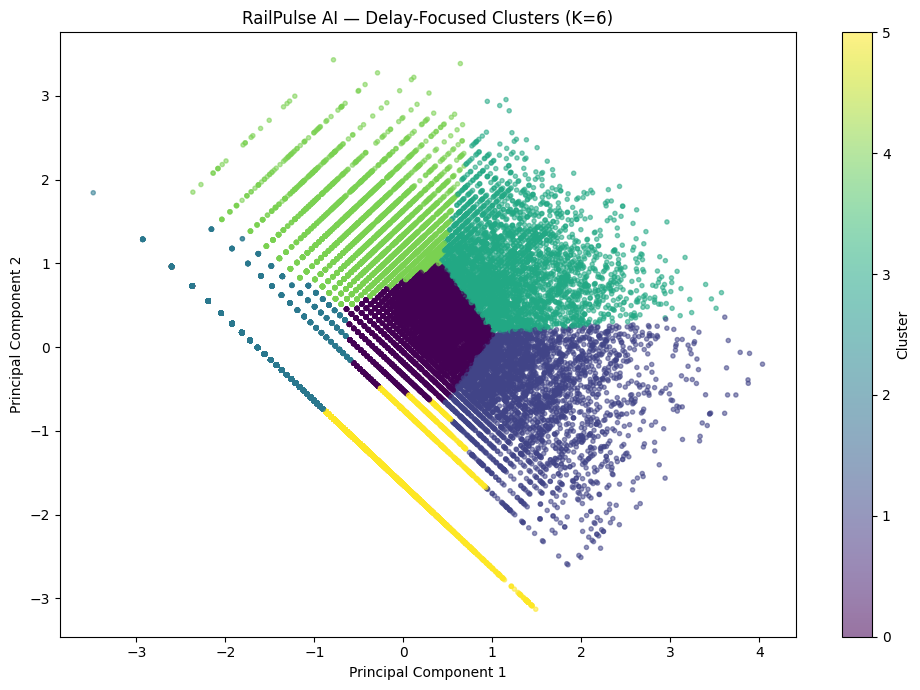


Figure saved: ../outputs/figures\09_delay_focused_clusters.png

Delay-focused clustering completed.


6652

In [2]:

# ============================================================
# RAILPULSE AI — DELAY-FOCUSED CLUSTERING
# Excluding Route Position Features
# ============================================================

import os
import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score
)

OUTPUT_DIR = "../outputs/tables"
FIGURE_DIR = "../outputs/figures"

os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(FIGURE_DIR, exist_ok=True)

RANDOM_STATE = 42

# ------------------------------------------------------------
# 1. SELECT DELAY-FOCUSED FEATURES
# ------------------------------------------------------------

FOCUSED_FEATURES = [
    "current_arr_delay",
    "distance_to_next"
]

X_focused_original = sample_df[
    FOCUSED_FEATURES
].copy()

# Log transform to reduce extreme-value influence
X_focused = np.log1p(
    X_focused_original
)

# Standardize
focused_scaler = StandardScaler()

X_focused_scaled = focused_scaler.fit_transform(
    X_focused
).astype(np.float32)

print("=" * 70)
print("RAILPULSE AI — DELAY-FOCUSED CLUSTERING")
print("=" * 70)

print("Sample size:", len(X_focused_scaled))
print("Features:", FOCUSED_FEATURES)

# ------------------------------------------------------------
# 2. PCA
# ------------------------------------------------------------

focused_pca = PCA(
    n_components=2,
    random_state=RANDOM_STATE
)

X_focused_pca = focused_pca.fit_transform(
    X_focused_scaled
)

focused_variance = (
    focused_pca.explained_variance_ratio_
)

print("\nPCA RESULTS")
print("PC1:", round(focused_variance[0] * 100, 3), "%")
print("PC2:", round(focused_variance[1] * 100, 3), "%")
print(
    "Total:",
    round(focused_variance.sum() * 100, 3),
    "%"
)

# ------------------------------------------------------------
# 3. EVALUATE K = 2 TO 6
# ------------------------------------------------------------

focused_metrics = []

print("\nEvaluating K-Means...")

for k in range(2, 7):

    print(f"Testing K={k}")

    model = KMeans(
        n_clusters=k,
        n_init=10,
        max_iter=300,
        random_state=RANDOM_STATE
    )

    labels = model.fit_predict(
        X_focused_scaled
    )

    silhouette = silhouette_score(
        X_focused_scaled,
        labels,
        sample_size=min(5000, len(X_focused_scaled)),
        random_state=RANDOM_STATE
    )

    db_score = davies_bouldin_score(
        X_focused_scaled,
        labels
    )

    focused_metrics.append({
        "K": k,
        "Inertia": model.inertia_,
        "Silhouette_Score": silhouette,
        "Davies_Bouldin_Score": db_score
    })

    print(
        f"Silhouette: {silhouette:.4f} | "
        f"Davies-Bouldin: {db_score:.4f}"
    )

    del model, labels
    gc.collect()

focused_metrics_df = pd.DataFrame(
    focused_metrics
)

print("\nCLUSTER SELECTION RESULTS")
print(
    focused_metrics_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

focused_metrics_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "delay_focused_cluster_metrics.csv"
    ),
    index=False
)

# ------------------------------------------------------------
# 4. SELECT BEST K BY SILHOUETTE
# ------------------------------------------------------------

focused_best_k = int(
    focused_metrics_df.loc[
        focused_metrics_df["Silhouette_Score"].idxmax(),
        "K"
    ]
)

print("\nBest silhouette-based K:", focused_best_k)

# ------------------------------------------------------------
# 5. FIT FINAL DELAY-FOCUSED K-MEANS
# ------------------------------------------------------------

focused_kmeans = KMeans(
    n_clusters=focused_best_k,
    n_init=10,
    max_iter=300,
    random_state=RANDOM_STATE
)

focused_labels = focused_kmeans.fit_predict(
    X_focused_scaled
)

focused_clustered = X_focused_original.copy()

focused_clustered["next_arr_delay"] = (
    sample_df["next_arr_delay"].to_numpy()
)

focused_clustered["cluster"] = focused_labels

# ------------------------------------------------------------
# 6. PROFILE CLUSTERS
# ------------------------------------------------------------

focused_profile = focused_clustered.groupby(
    "cluster"
).agg(
    observations=("current_arr_delay", "size"),
    mean_current_delay=("current_arr_delay", "mean"),
    median_current_delay=("current_arr_delay", "median"),
    mean_next_delay=("next_arr_delay", "mean"),
    median_next_delay=("next_arr_delay", "median"),
    mean_distance_to_next=("distance_to_next", "mean"),
    median_distance_to_next=("distance_to_next", "median")
).reset_index()

focused_profile["percentage"] = (
    focused_profile["observations"] /
    len(focused_clustered) * 100
)

print("\n" + "=" * 80)
print("DELAY-FOCUSED CLUSTER PROFILES")
print("=" * 80)

print(
    focused_profile.to_string(
        index=False,
        float_format=lambda x: f"{x:.2f}"
    )
)

focused_profile.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "delay_focused_cluster_profiles.csv"
    ),
    index=False
)

# ------------------------------------------------------------
# 7. VISUALIZE PCA CLUSTERS
# ------------------------------------------------------------

plt.figure(figsize=(10, 7))

scatter = plt.scatter(
    X_focused_pca[:, 0],
    X_focused_pca[:, 1],
    c=focused_labels,
    cmap="viridis",
    s=9,
    alpha=0.55
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.title(
    f"RailPulse AI — Delay-Focused Clusters (K={focused_best_k})"
)

plt.colorbar(
    scatter,
    label="Cluster"
)

plt.tight_layout()

focused_figure_path = os.path.join(
    FIGURE_DIR,
    "09_delay_focused_clusters.png"
)

plt.savefig(
    focused_figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nFigure saved:", focused_figure_path)

# ------------------------------------------------------------
# 8. SAVE CLUSTERED SAMPLE
# ------------------------------------------------------------

focused_clustered.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "delay_focused_clustered_sample.csv"
    ),
    index=False
)

print("\nDelay-focused clustering completed.")

# Release temporary arrays
del X_focused_original
del X_focused
del X_focused_scaled
del X_focused_pca
del focused_labels
del focused_kmeans
del focused_scaler
del focused_pca

gc.collect()
